# Optimization and Gradient Descent

Training a model means choosing parameters that minimize a loss function. Gradient descent is the
workhorse behind linear regression, logistic regression, and neural networks. This notebook builds
the method from scratch so the optimizer is no longer a black box.

## Learning objectives

By the end of this notebook you can:

- explain loss surfaces and convexity;
- compute gradients and verify them numerically;
- implement gradient descent and tune the learning rate;
- train linear regression with batch, mini-batch, and stochastic gradient descent;
- use momentum and early stopping to improve optimization.

## 1. Loss functions and parameter space

A loss function $L(w)$ measures how wrong a model with parameters $w$ is. The goal is

$$ w^* = \arg\min_w L(w) $$

A **convex** function has a single global minimum. A non-convex function can have local minima,
plateaus, and saddle points. Neural networks are non-convex, yet gradient-based optimization still
works well in practice.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

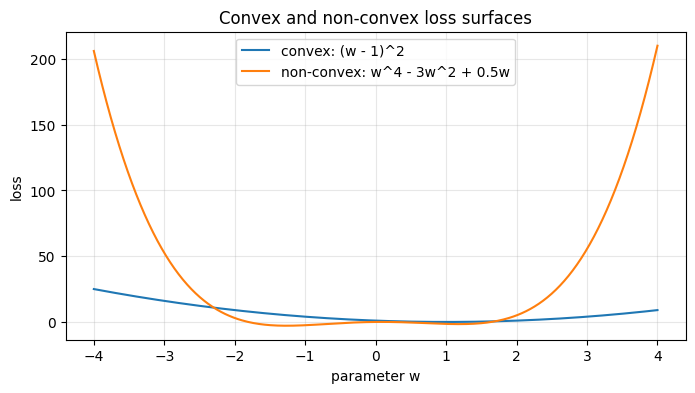

In [2]:
w = np.linspace(-4, 4, 400)

convex = (w - 1) ** 2
nonconvex = w ** 4 - 3 * w ** 2 + 0.5 * w

plt.figure(figsize=(8, 4))
plt.plot(w, convex, label="convex: (w - 1)^2")
plt.plot(w, nonconvex, label="non-convex: w^4 - 3w^2 + 0.5w")
plt.xlabel("parameter w")
plt.ylabel("loss")
plt.title("Convex and non-convex loss surfaces")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The derivative tells us the local slope. For one parameter, move opposite the slope to decrease the
loss. For many parameters, the **gradient** $\nabla L(w)$ is the vector of partial derivatives and
points in the direction of steepest increase.

In [3]:
def f(w):
    return (w - 1) ** 2

def grad_f(w):
    return 2 * (w - 1)

for point in [-2.0, 0.0, 1.0, 3.0]:
    print(f"w={point:>4}: f(w)={f(point):.2f}, f'(w)={grad_f(point):.2f}")

w=-2.0: f(w)=9.00, f'(w)=-6.00
w= 0.0: f(w)=1.00, f'(w)=-2.00
w= 1.0: f(w)=0.00, f'(w)=0.00
w= 3.0: f(w)=4.00, f'(w)=4.00


### Numerical gradient check

A derivative can be approximated with a finite difference:

$$ \frac{\partial L}{\partial w_i} \approx
\frac{L(w + \epsilon e_i) - L(w - \epsilon e_i)}{2\epsilon} $$

Always check a hand-written gradient against this approximation before trusting a training loop.

In [4]:
def numerical_gradient(fn, w, eps=1e-6):
    grad = np.zeros_like(w, dtype=float)
    for i in range(len(w)):
        step = np.zeros_like(w, dtype=float)
        step[i] = eps
        grad[i] = (fn(w + step) - fn(w - step)) / (2 * eps)
    return grad

def quadratic_loss(w):
    return np.sum((w - np.array([1.0, -2.0, 0.5])) ** 2)

def quadratic_grad(w):
    return 2 * (w - np.array([1.0, -2.0, 0.5]))

w0 = np.array([2.0, 1.0, -1.0])
print("analytic gradient: ", quadratic_grad(w0))
print("numerical gradient:", numerical_gradient(quadratic_loss, w0))
print("max difference:    ", np.max(np.abs(quadratic_grad(w0) - numerical_gradient(quadratic_loss, w0))))

analytic gradient:  [ 2.  6. -3.]
numerical gradient: [ 2.  6. -3.]
max difference:     8.386678018723615e-10


## 2. Gradient descent

The update rule is

$$ w_{t+1} = w_t - \eta \nabla L(w_t) $$

where $\eta$ is the learning rate. Too small and training is slow; too large and the parameters
oscillate or diverge. The learning rate is one of the most important hyperparameters in ML.

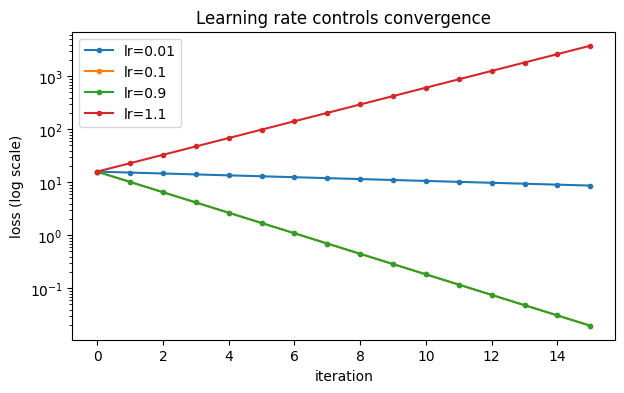

In [5]:
def gradient_descent_1d(start, learning_rate, steps=20):
    path = [start]
    w = start
    for _ in range(steps):
        w = w - learning_rate * grad_f(w)
        path.append(w)
    return np.array(path)

learning_rates = [0.01, 0.1, 0.9, 1.1]
plt.figure(figsize=(7, 4))
for lr in learning_rates:
    path = gradient_descent_1d(-3.0, lr, steps=15)
    losses = f(path)
    plt.plot(losses, marker="o", markersize=3, label=f"lr={lr}")
plt.yscale("log")
plt.xlabel("iteration")
plt.ylabel("loss (log scale)")
plt.title("Learning rate controls convergence")
plt.legend()
plt.show()

In [6]:
for lr in learning_rates:
    path = gradient_descent_1d(-3.0, lr, steps=15)
    print(f"lr={lr:<4} final w={path[-1]:>8.3f} final loss={f(path[-1]):>10.3f}")

lr=0.01 final w=  -1.954 final loss=     8.728
lr=0.1  final w=   0.859 final loss=     0.020
lr=0.9  final w=   1.141 final loss=     0.020
lr=1.1  final w=  62.628 final loss=  3798.021


A learning rate near 1.0 converges in one step for this quadratic because the curvature is 2. A rate
above 1.0 overshoots and diverges. Real loss surfaces have different curvature in different
directions, so a single rate is a compromise.

## 3. Linear regression from scratch

For linear regression with mean squared error,

$$ L(w) = \frac{1}{n} \|Xw - y\|_2^2, \qquad
\nabla L(w) = \frac{2}{n} X^T(Xw - y) $$

We add an intercept column, standardize the features, and compare gradient descent with the
closed-form least-squares solution.

In [7]:
from sklearn.datasets import make_regression
from sklearn.preprocessing import StandardScaler

X, y = make_regression(
    n_samples=400, n_features=5, n_informative=4, noise=8.0, random_state=42
)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_design = np.column_stack([np.ones(len(X_scaled)), X_scaled])

def mse_loss(w, X, y):
    residual = X @ w - y
    return np.mean(residual ** 2)

def mse_gradient(w, X, y):
    return (2.0 / len(y)) * X.T @ (X @ w - y)

def batch_gradient_descent(X, y, learning_rate=0.1, steps=200):
    w = np.zeros(X.shape[1])
    history = [mse_loss(w, X, y)]
    for _ in range(steps):
        w = w - learning_rate * mse_gradient(w, X, y)
        history.append(mse_loss(w, X, y))
    return w, np.array(history)

w_gd, loss_history = batch_gradient_descent(X_design, y)
w_closed = np.linalg.lstsq(X_design, y, rcond=None)[0]

print("final GD loss:      ", mse_loss(w_gd, X_design, y))
print("closed-form loss:   ", mse_loss(w_closed, X_design, y))
print("max coefficient gap:", np.max(np.abs(w_gd - w_closed)))

final GD loss:       60.07077177076817
closed-form loss:    60.07077177076817
max coefficient gap: 1.4210854715202004e-14


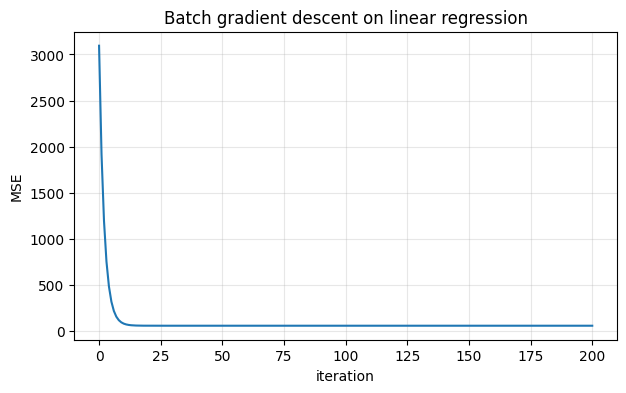

In [8]:
plt.figure(figsize=(7, 4))
plt.plot(loss_history)
plt.xlabel("iteration")
plt.ylabel("MSE")
plt.title("Batch gradient descent on linear regression")
plt.grid(alpha=0.3)
plt.show()

## 4. Stochastic and mini-batch gradient descent

Batch gradient descent uses all examples for one update. **Stochastic gradient descent (SGD)** uses
one example at a time; **mini-batch** uses a small subset. The noisy updates can escape shallow local
minima and are much cheaper per step, which is essential for large datasets.

One pass over the training data is an **epoch**. A typical training loop runs many epochs and shuffles
the data each epoch.

In [9]:
def sgd_linear_regression(X, y, learning_rate=0.01, epochs=60, batch_size=1, seed=0):
    local_rng = np.random.default_rng(seed)
    w = np.zeros(X.shape[1])
    history = []
    for _ in range(epochs):
        order = local_rng.permutation(len(y))
        for start in range(0, len(y), batch_size):
            idx = order[start:start + batch_size]
            grad = mse_gradient(w, X[idx], y[idx])
            w = w - learning_rate * grad
        history.append(mse_loss(w, X, y))
    return w, np.array(history)

w_sgd, hist_sgd = sgd_linear_regression(
    X_design, y, learning_rate=0.01, epochs=60, batch_size=1
)
w_mini, hist_mini = sgd_linear_regression(
    X_design, y, learning_rate=0.05, epochs=60, batch_size=32
)

print("SGD final loss:      ", mse_loss(w_sgd, X_design, y))
print("mini-batch final loss:", mse_loss(w_mini, X_design, y))
print("closed-form loss:    ", mse_loss(w_closed, X_design, y))

SGD final loss:       63.540807148267575
mini-batch final loss: 60.30235598516177
closed-form loss:     60.07077177076817


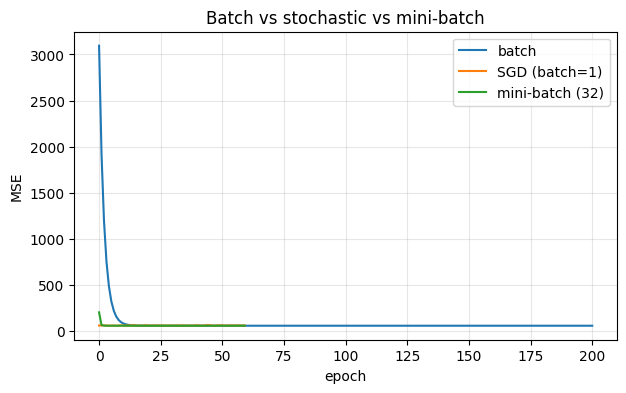

In [10]:
plt.figure(figsize=(7, 4))
plt.plot(loss_history, label="batch")
plt.plot(hist_sgd, label="SGD (batch=1)")
plt.plot(hist_mini, label="mini-batch (32)")
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.title("Batch vs stochastic vs mini-batch")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

SGD's loss is noisy because each update sees a different example. Mini-batch training balances the
stable gradient estimate of batch training with the speed and regularization effect of SGD.

## 5. Momentum

Momentum accumulates past gradients:

$$ v_{t+1} = \beta v_t + \nabla L(w_t), \qquad w_{t+1} = w_t - \eta v_{t+1} $$

It smooths noisy updates and speeds up movement along consistent directions. This is especially
useful for elongated loss surfaces where plain gradient descent zig-zags.

In [11]:
def momentum_gradient_descent(X, y, learning_rate=0.05, beta=0.9, steps=100):
    w = np.zeros(X.shape[1])
    velocity = np.zeros_like(w)
    history = [mse_loss(w, X, y)]
    for _ in range(steps):
        velocity = beta * velocity + mse_gradient(w, X, y)
        w = w - learning_rate * velocity
        history.append(mse_loss(w, X, y))
    return w, np.array(history)

w_plain, hist_plain = batch_gradient_descent(X_design, y, learning_rate=0.05, steps=100)
w_momentum, hist_momentum = momentum_gradient_descent(X_design, y, learning_rate=0.05, steps=100)

print("plain final loss:   ", mse_loss(w_plain, X_design, y))
print("momentum final loss:", mse_loss(w_momentum, X_design, y))

plain final loss:    60.07077240730008
momentum final loss: 60.11131942277334


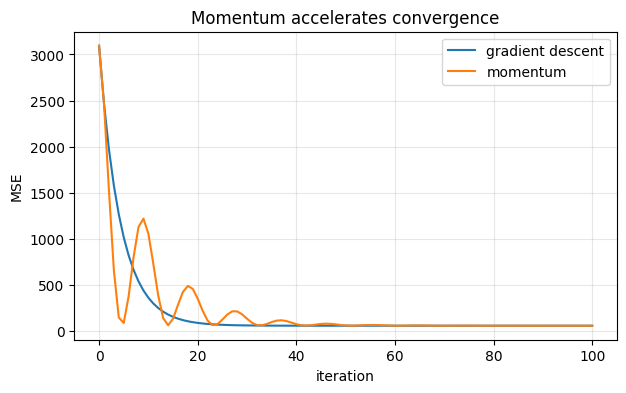

In [12]:
plt.figure(figsize=(7, 4))
plt.plot(hist_plain, label="gradient descent")
plt.plot(hist_momentum, label="momentum")
plt.xlabel("iteration")
plt.ylabel("MSE")
plt.title("Momentum accelerates convergence")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 6. Regularization and early stopping

Optimization and generalization are different goals. A model can drive training loss to zero while
overfitting. Two common controls are:

- **L2 regularization:** add $\lambda \|w\|_2^2$ to the loss, which adds $2\lambda w$ to the
  gradient.
- **Early stopping:** stop when validation loss stops improving.

Both keep the parameters from becoming too large or too tailored to the training set.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge

X_train, X_val, y_train, y_val = train_test_split(
    X_design, y, test_size=0.25, random_state=42
)

def train_with_early_stopping(X_train, y_train, X_val, y_val, learning_rate=0.05,
                              steps=400, patience=20):
    w = np.zeros(X_train.shape[1])
    best_w = w.copy()
    best_val = mse_loss(w, X_val, y_val)
    wait = 0
    train_curve, val_curve = [], []
    for _ in range(steps):
        w = w - learning_rate * mse_gradient(w, X_train, y_train)
        train_curve.append(mse_loss(w, X_train, y_train))
        val_curve.append(mse_loss(w, X_val, y_val))
        if val_curve[-1] < best_val - 1e-6:
            best_val = val_curve[-1]
            best_w = w.copy()
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break
    return best_w, np.array(train_curve), np.array(val_curve)

w_early, train_curve, val_curve = train_with_early_stopping(
    X_train, y_train, X_val, y_val
)
ridge = Ridge(alpha=1.0).fit(X_train[:, 1:], y_train)

print("early-stopping validation MSE:", mse_loss(w_early, X_val, y_val))
print("ridge validation MSE:         ", mse_loss(
    np.r_[ridge.intercept_, ridge.coef_], X_val, y_val
))

early-stopping validation MSE: 58.137165123878724
ridge validation MSE:          58.78344324523325


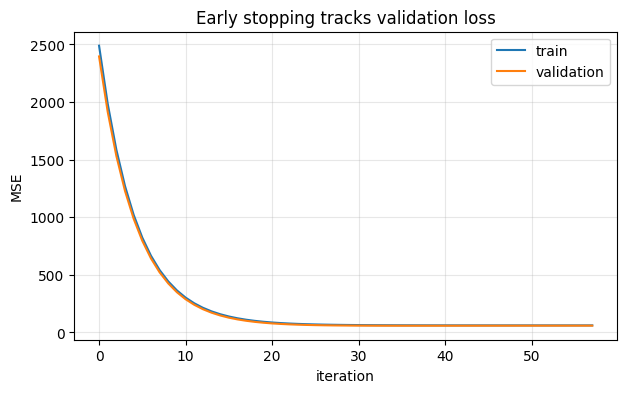

In [14]:
plt.figure(figsize=(7, 4))
plt.plot(train_curve, label="train")
plt.plot(val_curve, label="validation")
plt.xlabel("iteration")
plt.ylabel("MSE")
plt.title("Early stopping tracks validation loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 7. Summary

- A loss function defines the optimization objective; convexity determines how easy it is.
- The gradient points uphill, so subtract it to descend.
- The learning rate controls step size and stability.
- Batch, mini-batch, and stochastic gradient descent trade off stability and speed.
- Momentum smooths and accelerates optimization.
- Regularization and early stopping protect generalization, not just training loss.

## Exercises

1. Derive the gradient of MSE for linear regression on paper and verify it numerically.
2. Try learning rates 0.001, 0.01, 0.1, and 1.0 on the quadratic and describe the behavior.
3. Compare batch sizes 1, 8, 32, and 256 on the linear-regression example.
4. Add L2 regularization to the gradient-descent update and compare with `Ridge`.
5. Explain why a non-convex loss can still be optimized effectively with stochastic gradients.